In [118]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)
if not os.getenv("GROQ_API_KEY", "").strip():
    raise RuntimeError(
        "GROQ_API_KEY is missing. Add an active Groq API key to the project .env file, then restart the notebook kernel."
    )

In [119]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)
key = os.getenv("GROQ_API_KEY")
print("Key loaded:", bool(key), "Prefix:", key[:4] if key else None)

Key loaded: True Prefix: gsk_


In [120]:
from langgraph.graph import StateGraph, START, END

HouseholdProfile

In [121]:
from typing import Literal
from pydantic import BaseModel, Field


class HouseholdProfile(BaseModel):
    city: str
    latitude: float
    longitude: float

    commute_mode: Literal[
        "car",
        "two_wheeler",
        "transit",
        "walk_cycle",
        "remote"
    ] = "two_wheeler"

    daily_commute_km: float = 15.0

    has_sensitive_members: bool = False

    has_air_purifier: bool = False

test household

In [122]:
profile = HouseholdProfile(
    city="Delhi",
    latitude=28.61,
    longitude=77.20
)

profile


HouseholdProfile(city='Delhi', latitude=28.61, longitude=77.2, commute_mode='two_wheeler', daily_commute_km=15.0, has_sensitive_members=False, has_air_purifier=False)

ActionItem

In [123]:
from pydantic import BaseModel
from typing import Literal


class ActionItem(BaseModel):
    title: str

    category: Literal[
        "daily_routine",
        "indoor_air_hack",
        "sustainable_alternative"
    ]

    action_steps: list[str]

    estimated_impact: str

    tradeoff_or_note: str

test ActionItem

In [124]:
ActionItem(
    title="Use N95",
    category="daily_routine",
    action_steps=["Wear N95 outside"],
    estimated_impact="Reduces PM2.5 exposure",
    tradeoff_or_note="Less comfortable"
)

ActionItem(title='Use N95', category='daily_routine', action_steps=['Wear N95 outside'], estimated_impact='Reduces PM2.5 exposure', tradeoff_or_note='Less comfortable')

SmogAdvisoryResponse

In [125]:
class SmogAdvisoryResponse(BaseModel):

    city: str

    current_aqi_us: float | None

    pm25_ug_m3: float | None

    severity_band: str

    summary: str

    impact_summary: ImpactSummary

    recommendations: list[ActionItem]

    assumptions: list[str]

    disclaimer: str

In [126]:
import httpx

url data test

In [127]:
lat = 28.61
lon = 77.20

url = "https://air-quality-api.open-meteo.com/v1/air-quality"

params = {
    "latitude": lat,
    "longitude": lon,
    "current": "pm10,pm2_5,nitrogen_dioxide,us_aqi"
}

resp = httpx.get(url, params=params)

resp.json()

{'latitude': 28.599998,
 'longitude': 77.20001,
 'generationtime_ms': 0.28765201568603516,
 'utc_offset_seconds': 0,
 'timezone': 'GMT',
 'timezone_abbreviation': 'GMT',
 'elevation': 221.0,
 'current_units': {'time': 'iso8601',
  'interval': 'seconds',
  'pm10': 'μg/m³',
  'pm2_5': 'μg/m³',
  'nitrogen_dioxide': 'μg/m³',
  'us_aqi': 'USAQI'},
 'current': {'time': '2026-11-26T10:00',
  'interval': 3600,
  'pm10': 48.8,
  'pm2_5': 46.8,
  'nitrogen_dioxide': 31.8,
  'us_aqi': 198}}

In [128]:
def fetch_aqi_node(state):
    print("STATE received:", state)
    profile = state["profile"]

    url = "https://air-quality-api.open-meteo.com/v1/air-quality"

    params = {
        "latitude": profile.latitude,
        "longitude": profile.longitude,
        "current": "pm10,pm2_5,nitrogen_dioxide,us_aqi",
    }

    data = httpx.get(
        url,
        params=params
    ).json()

    current = data["current"]

    return {
        "aqi_payload": {
            "pm25": current["pm2_5"],
            "us_aqi": current["us_aqi"]
        }
    }

In [129]:
def classify_severity(pm25):

    if pm25 >= 150:
        return "severe"

    if pm25 >= 55.5:
        return "unhealthy"

    if pm25 >= 35.5:
        return "unhealthy_sensitive"

    if pm25 >= 12:
        return "moderate"

    return "low"

In [130]:
classify_severity(70)

'unhealthy'

In [131]:
def compute_metrics(profile, pm25):

    emission_factors = {
        "car": 0.17,
        "two_wheeler": 0.06,
        "transit": 0.04,
        "walk_cycle": 0.0,
        "remote": 0.0
    }

    ef = emission_factors[profile.commute_mode]

    avoidable_km = round(profile.daily_commute_km * 0.30, 2)

    daily_co2_saved = round(avoidable_km * ef, 3)

    annual_co2_saved = round(daily_co2_saved * 365, 2)

    indoor_reduction_pct = (
        75 if profile.has_air_purifier
        else 45
    )

    estimated_indoor_pm25 = round(
        pm25 * (1 - indoor_reduction_pct / 100),
        2
    )

    return {
        "avoidable_km": avoidable_km,

        "daily_co2_saved_kg": daily_co2_saved,

        "annual_co2_saved_kg": annual_co2_saved,

        "outdoor_pm25": pm25,

        "estimated_indoor_pm25":
            estimated_indoor_pm25,

        "indoor_exposure_reduction_pct":
            indoor_reduction_pct,

        "severity":
            classify_severity(pm25)
    }


test metrics

In [132]:
metrics = compute_metrics(profile, 90)

metrics

{'avoidable_km': 4.5,
 'daily_co2_saved_kg': 0.27,
 'annual_co2_saved_kg': 98.55,
 'outdoor_pm25': 90,
 'estimated_indoor_pm25': 49.5,
 'indoor_exposure_reduction_pct': 45,
 'severity': 'unhealthy'}

In [133]:
class ImpactSummary(BaseModel):

    daily_co2_saved_kg: float

    annual_co2_saved_kg: float

    outdoor_pm25: float

    estimated_indoor_pm25: float

    exposure_reduction_pct: float

In [134]:
def compute_impact_node(state):

    profile = state["profile"]

    aqi = state["aqi_payload"]

    metrics = compute_metrics(
        profile,
        aqi["pm25"]
    )

    return {
        "computed_metrics": metrics
    }

In [135]:
from langchain_google_genai import ChatGoogleGenerativeAI

In [ ]:
from langchain_groq import ChatGroq

groq_api_key = os.getenv("GROQ_API_KEY", "").strip()
if not groq_api_key:
    raise RuntimeError("GROQ_API_KEY is missing. Set it in the project .env file.")

llm = ChatGroq(model="openai/gpt-oss-120b", api_key=groq_api_key)

In [137]:
response = llm.invoke(
    "Why is PM2.5 dangerous?"
)

print(response.content)

**PM2.5** (particles ≤ 2.5 µm in aerodynamic diameter) is a major air‑pollution concern because its tiny size lets it behave very differently from larger dust or pollen. Below are the key reasons it is dangerous to human health and the environment.

---

## 1. Physical properties that make PM2.5 harmful  

| Property | Why it matters |
|----------|----------------|
| **Very small size (≤ 2.5 µm)** | Can stay suspended in air for days to weeks, traveling long distances from the source. |
| **Deep lung penetration** | Inhaled particles bypass the nose and upper airway, reaching the **alveoli** (the gas‑exchange sacs). |
| **Potential to enter the bloodstream** | Some ultrafine fractions (< 0.1 µm) can cross the alveolar–capillary barrier, reaching organs such as the heart, brain, and liver. |
| **Large surface‑area‑to‑mass ratio** | Provides a “platform” for toxic chemicals (heavy metals, polycyclic aromatic hydrocarbons, sulfates, nitrates, etc.) to adsorb, amplifying toxicity. |
| **Re

In [138]:
structured_llm = llm.with_structured_output(
    SmogAdvisoryResponse
)

In [139]:
response = structured_llm.invoke("""
Generate air quality advice for Delhi.
Current AQI 180.
PM2.5 = 85
with in 300 words.""")

response

SmogAdvisoryResponse(city='Delhi', current_aqi_us=180.0, pm25_ug_m3=85.0, severity_band='Unhealthy', summary='Delhi’s AQI of 180 places the air quality in the Unhealthy range. Outdoor PM2.5 at 85\u202fµg/m³ can aggravate respiratory and cardiovascular conditions, especially for children, seniors, and those with pre‑existing illnesses. Limit time spent outdoors, improve indoor air filtration, and choose low‑emission transport options to reduce exposure and cut daily CO₂ emissions by roughly 4\u202fkg per person.', impact_summary=ImpactSummary(daily_co2_saved_kg=4.1, annual_co2_saved_kg=1500.0, outdoor_pm25=85.0, estimated_indoor_pm25=55.0, exposure_reduction_pct=30.0), recommendations=[ActionItem(title='Limit Outdoor Activity', category='daily_routine', action_steps=['Avoid jogging, cycling, or prolonged walks outdoors.', 'If you must be outside, keep activity to under 15\u202fminutes.', 'Stay in shaded or low‑traffic areas.'], estimated_impact='Reduces personal inhaled PM2.5 by ~30\u20

In [ ]:
def generate_advisory_node(state):

    profile = state["profile"]

    metrics = state["computed_metrics"]

    structured_llm = llm.with_structured_output(
        SmogAdvisoryResponse
    )

    response = structured_llm.invoke(
        f"""
        Household Profile:
        {profile}

        AQI:
        {state["aqi_payload"]}


        Metrics:
        {metrics}

        Special Alert:
        {metrics.get("special_alert")}

        Create personalized smog guidance.

        Explain:

        1. How much CO2 the user saves daily.

        2. How much CO2 the user saves annually.

        3. Estimated indoor PM2.5 reduction.

        4. Difference between exposure reduction
        and pollution reduction.

        5. Give 3-5 actionable recommendations.
        """
    )
    return {
        "advisory": response
    }

In [ ]:
def route_by_severity(state):

    severity = state["computed_metrics"]["severity"]

    print("Severity:", severity)

    if severity in [
        "unhealthy",
        "severe",
        "unhealthy_sensitive"
    ]:
        return "high_risk"

    return "normal_risk"

In [142]:
def high_risk_node(state):

    return {
        "computed_metrics": {
            **state["computed_metrics"],
            "risk_level": "high",
            "special_alert":
                "Avoid outdoor exposure whenever possible."
        }
    }

In [143]:
def normal_risk_node(state):

    return {
        "computed_metrics": {
            **state["computed_metrics"],
            "risk_level": "normal",
            "special_alert":
                "Outdoor activity allowed with precautions."
        }
    }

In [144]:
from typing import TypedDict

class GraphState(TypedDict):
    profile: HouseholdProfile
    aqi_payload: dict
    computed_metrics: dict
    advisory: SmogAdvisoryResponse

In [145]:
##############test

{
    "profile": profile
}

{'profile': HouseholdProfile(city='Delhi', latitude=28.61, longitude=77.2, commute_mode='two_wheeler', daily_commute_km=15.0, has_sensitive_members=False, has_air_purifier=False)}

In [146]:
from langgraph.checkpoint.memory import MemorySaver, InMemorySaver

In [147]:
memory = InMemorySaver()

In [148]:
workflow = StateGraph(GraphState)

workflow.add_node(
    "fetch_aqi",
    fetch_aqi_node
)

workflow.add_node(
    "compute_impact",
    compute_impact_node
)

workflow.add_node(
    "generate_advisory",
    generate_advisory_node
)

workflow.add_node(
    "high_risk",
    high_risk_node
)

workflow.add_node(
    "normal_risk",
    normal_risk_node
)

workflow.add_edge(
    START,
    "fetch_aqi"
)

workflow.add_edge(
    "fetch_aqi",
    "compute_impact"
)
"""
workflow.add_edge(
    "compute_impact",
    "generate_advisory"
)
"""
workflow.add_conditional_edges(
    "compute_impact",
    route_by_severity,
    {
        "high_risk": "high_risk",
        "normal_risk": "normal_risk"
    }
)

workflow.add_edge(
    "high_risk",
    "generate_advisory"
)

workflow.add_edge(
    "normal_risk",
    "generate_advisory"
)

workflow.add_edge(
    "generate_advisory",
    END
)

graph = workflow.compile(checkpointer=memory)

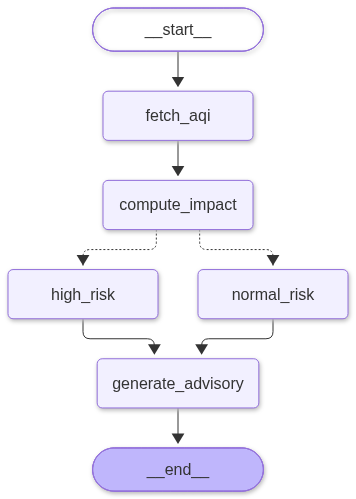

In [149]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [150]:
config = {
    "configurable": {
        "thread_id": "user_1"
    }
}

payload = {
    "profile": profile,
    "aqi_payload": {},
    "computed_metrics": {}
}

print(payload)

result = graph.invoke(
    payload,
    config=config
)

print(result)

{'profile': HouseholdProfile(city='Delhi', latitude=28.61, longitude=77.2, commute_mode='two_wheeler', daily_commute_km=15.0, has_sensitive_members=False, has_air_purifier=False), 'aqi_payload': {}, 'computed_metrics': {}}
STATE received: {'profile': HouseholdProfile(city='Delhi', latitude=28.61, longitude=77.2, commute_mode='two_wheeler', daily_commute_km=15.0, has_sensitive_members=False, has_air_purifier=False), 'aqi_payload': {}, 'computed_metrics': {}}
Severity: unhealthy_sensitive
{'profile': HouseholdProfile(city='Delhi', latitude=28.61, longitude=77.2, commute_mode='two_wheeler', daily_commute_km=15.0, has_sensitive_members=False, has_air_purifier=False), 'aqi_payload': {'pm25': 46.8, 'us_aqi': 198}, 'computed_metrics': {'avoidable_km': 4.5, 'daily_co2_saved_kg': 0.27, 'annual_co2_saved_kg': 98.55, 'outdoor_pm25': 46.8, 'estimated_indoor_pm25': 25.74, 'indoor_exposure_reduction_pct': 45, 'severity': 'unhealthy_sensitive', 'risk_level': 'normal', 'special_alert': 'Outdoor activi